<a href="https://colab.research.google.com/github/nicole205dev/Knowledge-Engineering/blob/main/Autonomous_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import heapq, math, copy
from collections import deque
import matplotlib.pyplot as plt

INF = float("inf")

Knowledge base and road network

Edges shorter than straight line (should be empty): []
9 nodes, 26 directed edges


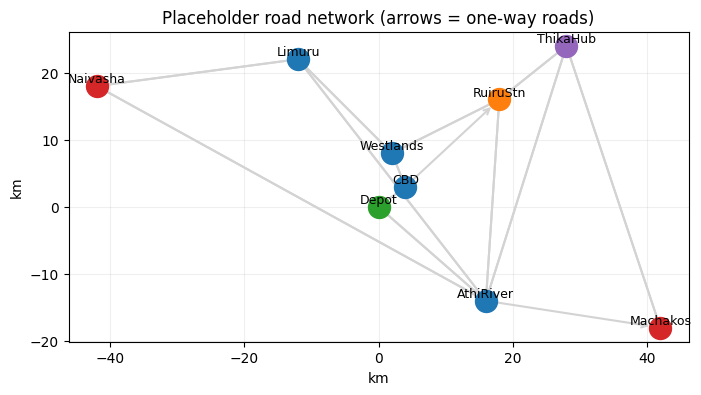

In [18]:
class KnowledgeBase:
    def __init__(self, fuel_capacity=12.0, consumption=0.5):
        self.nodes = {}              # name -> {"x", "y", "kind"}
        self.edges = {}              # (u, v) -> {"dist", "road", "status"}
        self.fuel_capacity = fuel_capacity   # litres
        self.consumption = consumption       # litres per km (clear weather)
        self.reserve = 1.0                   # litres that must never be used
        self.weather = "clear"               # "clear" or "rain"
        self.load_secured = True
        self.heuristic_table = None          # optional {(node, goal): h} from Exercise 3

    #  facts
    def add_node(self, name, x, y, kind="junction"):
        self.nodes[name] = {"x": x, "y": y, "kind": kind}

    def euclid(self, a, b):
        na, nb = self.nodes[a], self.nodes[b]
        return math.hypot(na["x"] - nb["x"], na["y"] - nb["y"])

    def add_edge(self, u, v, dist=None, road="paved", oneway=False):
        if dist is None:
            dist = round(self.euclid(u, v) * 1.2, 1)
        self.edges[(u, v)] = {"dist": dist, "road": road, "status": "open"}
        if not oneway:
            self.edges[(v, u)] = {"dist": dist, "road": road, "status": "open"}

    def set_status(self, u, v, status, both=True):
        changed = []
        for key in ((u, v), (v, u)) if both else ((u, v),):
            if key in self.edges:
                self.edges[key]["status"] = status
                changed.append(key)
        return changed

    # queries used by the planner
    def neighbors(self, u):
        for (a, b), e in self.edges.items():
            if a == u and e["status"] == "open":
                yield b, e["dist"]

    def h(self, n, goal):
        if self.heuristic_table is not None:
            return self.heuristic_table.get((n, goal), 0.0)
        return self.euclid(n, goal)

    def burn(self, dist):
        return dist * self.consumption * (1.25 if self.weather == "rain" else 1.0)

    def fuel_stations(self):
        return [n for n, d in self.nodes.items() if d["kind"] == "fuel"]

    def check_admissible(self):
        bad = [(k, e["dist"], round(self.euclid(*k), 2)) for k, e in self.edges.items()
               if e["dist"] + 1e-9 < self.euclid(*k)]
        return bad   # empty list means Euclidean heuristic is admissible and consistent

    def facts(self):
        out = [f"node({n}, kind={d['kind']})" for n, d in self.nodes.items()]
        out += [f"edge({u}->{v}, {e['dist']}km, {e['road']}, {e['status']})" for (u, v), e in self.edges.items()]
        out += [f"weather={self.weather}", f"load_secured={self.load_secured}"]
        return out


def build_world():
    """Kenyan road network (distances in km, coordinates in approx. km relative to Depot)."""
    kb = KnowledgeBase(fuel_capacity=120.0, consumption=0.35)
    kb.reserve = 10.0

    kb.add_node("Depot",     0.0,   0.0, "depot")        # Industrial Area, Nairobi
    kb.add_node("CBD",       4.0,   3.0)                 # Nairobi CBD
    kb.add_node("Westlands", 2.0,   8.0)                 # Westlands
    kb.add_node("RuiruStn", 18.0,  16.0, "fuel")         # Thika Rd / Ruiru fuel stop
    kb.add_node("ThikaHub", 28.0,  24.0, "loading")      # Thika logistics hub
    kb.add_node("Limuru",   -12.0,  22.0)                 # Limuru junction
    kb.add_node("AthiRiver", 16.0, -14.0)                 # Athi River junction
    kb.add_node("Naivasha", -42.0,  18.0, "destination")  # Naivasha inland destination
    kb.add_node("Machakos",  42.0, -18.0, "destination")  # Machakos eastern destination

    kb.add_edge("Depot", "CBD", dist=6.5)
    kb.add_edge("Depot", "AthiRiver", dist=22.0)
    kb.add_edge("CBD", "Westlands", dist=6.0)
    kb.add_edge("CBD", "RuiruStn", dist=21.5, oneway=True)
    kb.add_edge("Westlands", "Limuru", dist=24.0)
    kb.add_edge("Westlands", "RuiruStn", dist=23.0)
    kb.add_edge("RuiruStn", "ThikaHub", dist=14.5)
    kb.add_edge("RuiruStn", "AthiRiver", dist=34.0)
    kb.add_edge("ThikaHub", "AthiRiver", dist=46.0)
    kb.add_edge("ThikaHub", "Machakos", dist=52.0)
    kb.add_edge("Limuru", "AthiRiver", dist=58.0)
    kb.add_edge("Limuru", "Naivasha", dist=44.0, road="unpaved")
    kb.add_edge("AthiRiver", "Naivasha", dist=78.0)
    kb.add_edge("AthiRiver", "Machakos", dist=36.0, oneway=True)
    return kb


def plot_world(kb, path=None, title="Road network"):
    fig, ax = plt.subplots(figsize=(8, 5))
    colours = {"depot": "tab:green", "fuel": "tab:orange", "loading": "tab:purple",
               "destination": "tab:red", "junction": "tab:blue"}
    for (u, v), e in kb.edges.items():
        a, b = kb.nodes[u], kb.nodes[v]
        col = "lightgrey" if e["status"] == "open" else "red"
        style = "--" if e["status"] == "blocked" else "-"
        oneway = (v, u) not in kb.edges
        ax.annotate("", xy=(b["x"], b["y"]), xytext=(a["x"], a["y"]),
                    arrowprops=dict(arrowstyle="->" if oneway else "-", color=col, ls=style, lw=1.5,
                                    shrinkA=8, shrinkB=8))
    if path:
        for u, v in zip(path, path[1:]):
            a, b = kb.nodes[u], kb.nodes[v]
            ax.annotate("", xy=(b["x"], b["y"]), xytext=(a["x"], a["y"]),
                        arrowprops=dict(arrowstyle="->", color="black", lw=3, shrinkA=8, shrinkB=8))
    for n, d in kb.nodes.items():
        ax.scatter(d["x"], d["y"], s=250, color=colours[d["kind"]], zorder=3)
        ax.text(d["x"], d["y"] + 0.5, n, ha="center", fontsize=9)
    ax.set_title(title); ax.set_xlabel("km"); ax.set_ylabel("km"); ax.set_aspect("equal"); ax.grid(alpha=.2)
    plt.show()


kb_demo = build_world()
print("Edges shorter than straight line (should be empty):", kb_demo.check_admissible())
print(len(kb_demo.nodes), "nodes,", len(kb_demo.edges), "directed edges")
plot_world(kb_demo, title="Placeholder road network (arrows = one-way roads)")


Search algorithms

In [21]:
class Node:
    __slots__ = ("state", "parent", "g")
    def __init__(self, state, parent, g):
        self.state, self.parent, self.g = state, parent, g


def search(kb, start, goal, method="astar"):
    frontier = [Node(start, None, 0.0)]
    explored, order, tree = set(), [], []        # tree = list of (parent, child, g)
    best_g = {start: 0.0}
    while frontier:
        if method == "bfs":
            n = frontier.pop(0)
        elif method == "dfs":
            n = frontier.pop()
        else:
            key = {"ucs":    lambda x: x.g,
                   "greedy": lambda x: kb.h(x.state, goal),
                   "astar":  lambda x: x.g + kb.h(x.state, goal)}[method]
            n = min(frontier, key=key)
            frontier.remove(n)
        if n.state in explored:
            continue
        explored.add(n.state)
        order.append(n.state)
        tree.append((n.parent.state if n.parent else None, n.state, round(n.g, 2)))
        if n.state == goal:
            path, cur = [], n
            while cur:
                path.append(cur.state); cur = cur.parent
            return {"found": True, "path": path[::-1], "cost": round(n.g, 2),
                    "expanded": len(order), "order": order, "tree": tree, "method": method}
        for v, d in kb.neighbors(n.state):
            if v in explored:
                continue
            g = n.g + d
            if method in ("ucs", "astar"):
                if g >= best_g.get(v, INF):
                    continue
                best_g[v] = g
            frontier.append(Node(v, n, g))
    return {"found": False, "path": [], "cost": INF, "expanded": len(order),
            "order": order, "tree": tree, "method": method}


def print_tree(result):
    print(f"Search tree ({result['method']}), in expansion order  [parent -> node (g)]")
    for p, c, g in result["tree"]:
        print(f"  {p or 'START':>10} -> {c:<10} g={g}")


r = search(kb_demo, "Depot", "Machakos", "astar")
print("Path:", " -> ".join(r["path"]), "| cost:", r["cost"], "km | expanded:", r["expanded"])
print_tree(r)

Path: Depot -> AthiRiver -> Machakos | cost: 58.0 km | expanded: 4
Search tree (astar), in expansion order  [parent -> node (g)]
       START -> Depot      g=0.0
       Depot -> AthiRiver  g=22.0
       Depot -> CBD        g=6.5
   AthiRiver -> Machakos   g=58.0


Inference knowledge

In [22]:
class Rule:
    def __init__(self, name, description, condition, action):
        self.name, self.description, self.condition, self.action = name, description, condition, action


def make_rules():
    return [
        Rule("R1 LOAD_UNSECURED", "IF load not secured THEN hold position",
             lambda a: (not a.kb.load_secured) and not a.hold,
             lambda a: a.set_hold(True)),
        Rule("R2 LOAD_SECURED", "IF load secured AND holding THEN release hold",
             lambda a: a.kb.load_secured and a.hold,
             lambda a: a.set_hold(False)),
        Rule("R3 REFUEL", "IF at fuel station AND tank not full THEN refuel",
             lambda a: a.kb.nodes[a.loc]["kind"] == "fuel" and a.fuel < a.kb.fuel_capacity - 1e-9,
             lambda a: a.refuel()),
        Rule("R4 ARRIVED", "IF location == goal THEN stop and clear plan",
             lambda a: a.goal is not None and a.loc == a.goal,
             lambda a: a.arrive()),
        Rule("R5 BLOCKED_ROUTE", "IF a road on the plan is blocked THEN replan without it",
             lambda a: a.path and a.path_blocked(),
             lambda a: a.replan("a road on the planned route is blocked")),
        Rule("R6 FUEL_INSUFFICIENT", "IF plan not completable on current fuel THEN replan via fuel station",
             lambda a: a.path and not a.fuel_feasible(a.path),
             lambda a: a.replan("current fuel is not enough for the planned route")),
    ]

The agent

In [23]:
class TrailerAgent:
    def __init__(self, kb, start="Depot", fuel=None, method="astar", verbose=True):
        self.kb, self.loc = kb, start
        self.fuel = kb.fuel_capacity if fuel is None else fuel
        self.goal, self.path = None, []
        self.method, self.verbose = method, verbose
        self.hold, self.odometer = False, 0.0
        self.rules = make_rules()
        self.trace, self.last_plan_reason, self.last_search = [], "no plan yet", None

    # output
    def say(self, msg, tag="AGENT"):
        line = f"[{tag}] {msg}"
        self.trace.append(line)
        if self.verbose:
            print(line)

    #  actions used by rules
    def set_hold(self, value):
        self.hold = value
        self.say("Load is not secured: holding position." if value else "Load secured: hold released.", "RULE")

    def refuel(self):
        self.fuel = self.kb.fuel_capacity
        self.say(f"Refuelled at {self.loc} to {self.fuel:.1f} L.", "RULE")

    def arrive(self):
        self.say(f"Arrived at {self.loc}. Distance driven: {self.odometer:.1f} km, fuel left: {self.fuel:.1f} L.", "RULE")
        self.goal, self.path = None, []

    # knowledge helpers
    def path_blocked(self):
        return any(self.kb.edges[(a, b)]["status"] != "open" for a, b in zip(self.path, self.path[1:]))

    def fuel_feasible(self, path, start_fuel=None):
        f = self.fuel if start_fuel is None else start_fuel
        if self.kb.nodes[path[0]]["kind"] == "fuel":
            f = self.kb.fuel_capacity
        for a, b in zip(path, path[1:]):
            f -= self.kb.burn(self.kb.edges[(a, b)]["dist"])
            if f < self.kb.reserve:
                return False
            if self.kb.nodes[b]["kind"] == "fuel":
                f = self.kb.fuel_capacity
        return True

    #  planning
    def plan(self, goal, method=None):
        method = method or self.method
        self.goal = goal
        res = search(self.kb, self.loc, goal, method)
        self.last_search = res
        if not res["found"]:
            self.path = []
            self.last_plan_reason = f"No open route from {self.loc} to {goal}."
            self.say(self.last_plan_reason, "PLAN")
            return False
        options = []
        if self.fuel_feasible(res["path"]):
            options.append((res["cost"], res["path"], "shortest route is feasible on current fuel (counting refuels at fuel stations on the way)"))
        else:
            for fs in self.kb.fuel_stations():
                r1, r2 = search(self.kb, self.loc, fs, method), search(self.kb, fs, goal, method)
                if r1["found"] and r2["found"]:
                    p = r1["path"] + r2["path"][1:]
                    if self.fuel_feasible(p):
                        options.append((round(r1["cost"] + r2["cost"], 2), p, f"direct route needs more fuel than available, so routed via {fs}"))
        if not options:
            self.path = []
            self.last_plan_reason = f"{goal} cannot be reached safely with {self.fuel:.1f} L and no usable fuel stop."
            self.say(self.last_plan_reason, "PLAN")
            return False
        cost, path, why = min(options, key=lambda o: o[0])
        self.path = list(path)
        need = sum(self.kb.burn(self.kb.edges[(a, b)]["dist"]) for a, b in zip(path, path[1:]))
        self.last_plan_reason = (f"{method.upper()} chose {' -> '.join(path)} (cost {cost} km, est. fuel use {need:.1f} L, "
                                 f"{res['expanded']} nodes expanded); {why}. Weather: {self.kb.weather}.")
        self.say(self.last_plan_reason, "PLAN")
        return True

    def replan(self, cause):
        self.say(f"Replanning because {cause}.", "RULE")
        self.plan(self.goal)

    # inference
    def infer(self, max_passes=10):
        for _ in range(max_passes):
            fired = False
            for rule in self.rules:
                if rule.condition(self):
                    self.say(f"{rule.name} fired: {rule.description}", "INFER")
                    rule.action(self)
                    fired = True
            if not fired:
                return

    # acting
    def step(self):
        self.infer()
        if self.hold or len(self.path) < 2:
            return False
        a, b = self.path[0], self.path[1]
        d = self.kb.edges[(a, b)]["dist"]
        self.fuel -= self.kb.burn(d)
        self.odometer += d
        self.loc = b
        self.path.pop(0)
        self.say(f"Moved {a} -> {b} ({d} km). Fuel: {self.fuel:.1f} L.", "MOVE")
        self.infer()
        return True

    def drive(self, events=None, max_steps=40):
        events = events or {}
        for i in range(max_steps):
            for cmd in events.get(i, []):
                self.say(f"Event: {cmd}", "EVENT")
                print(ask(self, cmd))
            if not self.step():
                if self.goal is None or self.hold or not self.path:
                    break

    # explanation
    def explain(self):
        lines = ["Why this route?", "  " + self.last_plan_reason, "Recent rule firings:"]
        fired = [t for t in self.trace if t.startswith("[INFER]")][-5:]
        lines += ["  " + t for t in fired] or ["  (none yet)"]
        return "\n".join(lines)

Inference helpers

In [24]:
def compare(kb, start, goal):
    rows = []
    for m in ("bfs", "dfs", "ucs", "greedy", "astar"):
        r = search(kb, start, goal, m)
        rows.append((m.upper(), r["found"], r["cost"], r["expanded"], " -> ".join(r["path"])))
    out = [f"{'Method':<8}{'Found':<7}{'Cost(km)':<10}{'Expanded':<10}Path", "-" * 70]
    out += [f"{m:<8}{str(f):<7}{c:<10}{e:<10}{p}" for m, f, c, e, p in rows]
    return "\n".join(out)


HELP = ("Commands: route A B | goto B | go | why | compare A B | tree A B | block A B | unblock A B | "
        "fuel N | weather rain/clear | load secured/unsecured | status | facts | help | quit")

def ask(agent, text, quiet_agent=False):
    kb, parts = agent.kb, text.strip().split()
    if not parts:
        return ""
    cmd, args = parts[0].lower(), parts[1:]
    names = {n.lower(): n for n in kb.nodes}
    def node(i):
        key = args[i].lower() if len(args) > i else ""
        if key not in names:
            raise ValueError(f"unknown location '{args[i] if len(args) > i else ''}'. Known: {', '.join(kb.nodes)}")
        return names[key]
    old_verbose = agent.verbose
    agent.verbose = old_verbose and not quiet_agent
    try:
        if cmd == "route":
            a, b = node(0), node(1)
            r = search(kb, a, b, "astar")
            if not r["found"]:
                return f"No open route from {a} to {b}."
            return (f"Best route: {' -> '.join(r['path'])}\nDistance: {r['cost']} km, "
                    f"fuel needed ~{sum(kb.burn(kb.edges[(x, y)]['dist']) for x, y in zip(r['path'], r['path'][1:])):.1f} L, "
                    f"nodes expanded: {r['expanded']}")
        if cmd == "goto":
            ok = agent.plan(node(0)); return "Plan ready." if ok else "No safe plan found."
        if cmd == "go":
            agent.drive(); return "Done."
        if cmd == "why":
            return agent.explain()
        if cmd == "compare":
            return compare(kb, node(0), node(1))
        if cmd == "tree":
            r = search(kb, node(0), node(1), "astar")
            return "\n".join(f"{p or 'START':>10} -> {c:<10} g={g}" for p, c, g in r["tree"])
        if cmd in ("block", "unblock"):
            changed = kb.set_status(node(0), node(1), "blocked" if cmd == "block" else "open")
            if not changed:
                return "No such road."
            agent.infer()
            return f"{cmd.capitalize()}ed road {node(0)}-{node(1)}."
        if cmd == "fuel":
            agent.fuel = min(float(args[0]), kb.fuel_capacity); agent.infer(); return f"Fuel set to {agent.fuel:.1f} L."
        if cmd == "weather":
            kb.weather = args[0].lower(); agent.infer(); return f"Weather set to {kb.weather}."
        if cmd == "load":
            kb.load_secured = args[0].lower() == "secured"; agent.infer(); return f"Load secured = {kb.load_secured}."
        if cmd == "status":
            return (f"Location: {agent.loc} | Fuel: {agent.fuel:.1f}/{kb.fuel_capacity} L | Goal: {agent.goal} | "
                    f"Plan: {' -> '.join(agent.path) or '-'} | Hold: {agent.hold} | Weather: {kb.weather}")
        if cmd == "facts":
            return "\n".join(kb.facts())
        if cmd == "help":
            return HELP
        return "Unknown command. " + HELP
    except (ValueError, IndexError) as e:
        return f"Could not do that: {e}"
    finally:
        agent.verbose = old_verbose

Scenario 1,Normal delivery

[PLAN] ASTAR chose Depot -> AthiRiver -> Machakos (cost 58.0 km, est. fuel use 20.3 L, 4 nodes expanded); shortest route is feasible on current fuel (counting refuels at fuel stations on the way). Weather: clear.
[MOVE] Moved Depot -> AthiRiver (22.0 km). Fuel: 112.3 L.
[MOVE] Moved AthiRiver -> Machakos (36.0 km). Fuel: 99.7 L.
[INFER] R4 ARRIVED fired: IF location == goal THEN stop and clear plan
[RULE] Arrived at Machakos. Distance driven: 58.0 km, fuel left: 99.7 L.


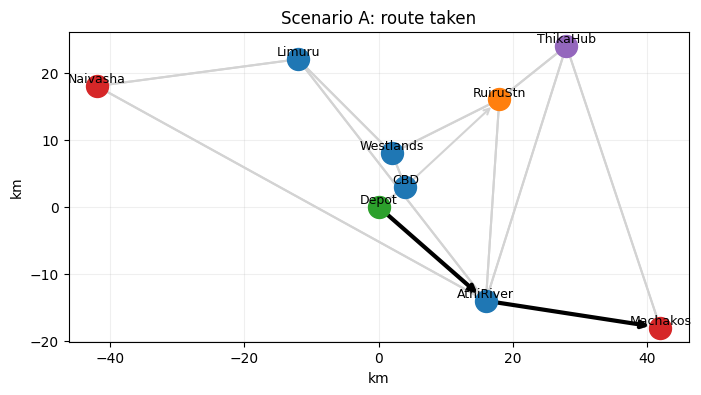


Why this route?
  ASTAR chose Depot -> AthiRiver -> Machakos (cost 58.0 km, est. fuel use 20.3 L, 4 nodes expanded); shortest route is feasible on current fuel (counting refuels at fuel stations on the way). Weather: clear.
Recent rule firings:
  [INFER] R4 ARRIVED fired: IF location == goal THEN stop and clear plan


In [26]:
kb = build_world()
agent = TrailerAgent(kb)
agent.plan("Machakos")
agent.drive()

moves = [line.split() for line in agent.trace if line.startswith("[MOVE]")]
driven_path = [moves[0][2]] + [m[4] for m in moves] if moves else None

plot_world(kb, path=driven_path, title="Scenario A: route taken")
print()
print(agent.explain())

Scenatio 2.blocked mid-journey

In [27]:
kb = build_world()
agent = TrailerAgent(kb)
agent.plan("Machakos")
agent.drive(events={1: ["block RuiruStn AthiRiver"]})

[PLAN] ASTAR chose Depot -> AthiRiver -> Machakos (cost 58.0 km, est. fuel use 20.3 L, 4 nodes expanded); shortest route is feasible on current fuel (counting refuels at fuel stations on the way). Weather: clear.
[MOVE] Moved Depot -> AthiRiver (22.0 km). Fuel: 112.3 L.
[EVENT] Event: block RuiruStn AthiRiver
Blocked road RuiruStn-AthiRiver.
[MOVE] Moved AthiRiver -> Machakos (36.0 km). Fuel: 99.7 L.
[INFER] R4 ARRIVED fired: IF location == goal THEN stop and clear plan
[RULE] Arrived at Machakos. Distance driven: 58.0 km, fuel left: 99.7 L.


Scenario 3,low fuel forces a refuel stop

In [28]:
kb = build_world()
agent = TrailerAgent(kb, fuel=28.0)
agent.plan("Naivasha")
agent.drive()

[PLAN] ASTAR chose Depot -> CBD -> RuiruStn -> Westlands -> Limuru -> Naivasha (cost 119.0 km, est. fuel use 41.6 L, 5 nodes expanded); direct route needs more fuel than available, so routed via RuiruStn. Weather: clear.
[MOVE] Moved Depot -> CBD (6.5 km). Fuel: 25.7 L.
[MOVE] Moved CBD -> RuiruStn (21.5 km). Fuel: 18.2 L.
[INFER] R3 REFUEL fired: IF at fuel station AND tank not full THEN refuel
[RULE] Refuelled at RuiruStn to 120.0 L.
[MOVE] Moved RuiruStn -> Westlands (23.0 km). Fuel: 112.0 L.
[MOVE] Moved Westlands -> Limuru (24.0 km). Fuel: 103.6 L.
[MOVE] Moved Limuru -> Naivasha (44.0 km). Fuel: 88.2 L.
[INFER] R4 ARRIVED fired: IF location == goal THEN stop and clear plan
[RULE] Arrived at Naivasha. Distance driven: 119.0 km, fuel left: 88.2 L.


Scenario 4,unsecured load

In [29]:
kb = build_world()
kb.load_secured = False
agent = TrailerAgent(kb)
agent.plan("Machakos")
agent.drive(max_steps=2)
print("--- driver secures the load ---")
kb.load_secured = True
agent.drive()

[PLAN] ASTAR chose Depot -> AthiRiver -> Machakos (cost 58.0 km, est. fuel use 20.3 L, 4 nodes expanded); shortest route is feasible on current fuel (counting refuels at fuel stations on the way). Weather: clear.
[INFER] R1 LOAD_UNSECURED fired: IF load not secured THEN hold position
[RULE] Load is not secured: holding position.
--- driver secures the load ---
[INFER] R2 LOAD_SECURED fired: IF load secured AND holding THEN release hold
[RULE] Load secured: hold released.
[MOVE] Moved Depot -> AthiRiver (22.0 km). Fuel: 112.3 L.
[MOVE] Moved AthiRiver -> Machakos (36.0 km). Fuel: 99.7 L.
[INFER] R4 ARRIVED fired: IF location == goal THEN stop and clear plan
[RULE] Arrived at Machakos. Distance driven: 58.0 km, fuel left: 99.7 L.


Scenario 5,rain and unreachable destination

In [30]:
kb = build_world()
agent = TrailerAgent(kb, fuel=25.0)
kb.weather = "rain"
print("Rain: fuel burn x1.25, tank at 25.0 L")
agent.plan("Machakos")
print()
print("--- now every road into Machakos is blocked ---")
kb.set_status("ThikaHub", "Machakos", "blocked"); kb.set_status("AthiRiver", "Machakos", "blocked")
agent2 = TrailerAgent(kb)
agent2.plan("Machakos")

Rain: fuel burn x1.25, tank at 25.0 L
[PLAN] ASTAR chose Depot -> CBD -> RuiruStn -> ThikaHub -> Machakos (cost 94.5 km, est. fuel use 41.3 L, 4 nodes expanded); direct route needs more fuel than available, so routed via RuiruStn. Weather: rain.

--- now every road into Machakos is blocked ---
[PLAN] No open route from Depot to Machakos.


False

Algorithm comparison

In [31]:
kb = build_world()
for s, g in [("Depot", "Machakos"), ("Depot", "Naivasha"), ("Limuru", "Machakos")]:
    print(f"{s} -> {g}"); print(compare(kb, s, g)); print()

Depot -> Machakos
Method  Found  Cost(km)  Expanded  Path
----------------------------------------------------------------------
BFS     True   58.0      9         Depot -> AthiRiver -> Machakos
DFS     True   58.0      3         Depot -> AthiRiver -> Machakos
UCS     True   58.0      8         Depot -> AthiRiver -> Machakos
GREEDY  True   58.0      3         Depot -> AthiRiver -> Machakos
ASTAR   True   58.0      4         Depot -> AthiRiver -> Machakos

Depot -> Naivasha
Method  Found  Cost(km)  Expanded  Path
----------------------------------------------------------------------
BFS     True   100.0     8         Depot -> AthiRiver -> Naivasha
DFS     True   215.5     8         Depot -> AthiRiver -> Machakos -> ThikaHub -> RuiruStn -> Westlands -> Limuru -> Naivasha
UCS     True   80.5      9         Depot -> CBD -> Westlands -> Limuru -> Naivasha
GREEDY  True   80.5      5         Depot -> CBD -> Westlands -> Limuru -> Naivasha
ASTAR   True   80.5      5         Depot -> CBD -> Wes

UI

In [32]:
def chat(agent):
    print("Autonomous Trailer ready. " + HELP)
    while True:
        text = input("you> ")
        if text.strip().lower() in ("quit", "exit"):
            break
        print(ask(agent, text))

# Scripted demo of the interface (run chat(agent) for a live session)
kb = build_world(); agent = TrailerAgent(kb)
for c in ["route Depot Naivasha", "goto Naivasha", "status", "block Limuru Naivasha", "why", "go", "status"]:
    print(f"you> {c}"); print(ask(agent, c)); print()

you> route Depot Naivasha
Best route: Depot -> CBD -> Westlands -> Limuru -> Naivasha
Distance: 80.5 km, fuel needed ~28.2 L, nodes expanded: 5

you> goto Naivasha
[PLAN] ASTAR chose Depot -> CBD -> Westlands -> Limuru -> Naivasha (cost 80.5 km, est. fuel use 28.2 L, 5 nodes expanded); shortest route is feasible on current fuel (counting refuels at fuel stations on the way). Weather: clear.
Plan ready.

you> status
Location: Depot | Fuel: 120.0/120.0 L | Goal: Naivasha | Plan: Depot -> CBD -> Westlands -> Limuru -> Naivasha | Hold: False | Weather: clear

you> block Limuru Naivasha
[INFER] R5 BLOCKED_ROUTE fired: IF a road on the plan is blocked THEN replan without it
[RULE] Replanning because a road on the planned route is blocked.
[PLAN] ASTAR chose Depot -> AthiRiver -> Naivasha (cost 100.0 km, est. fuel use 35.0 L, 7 nodes expanded); shortest route is feasible on current fuel (counting refuels at fuel stations on the way). Weather: clear.
Blocked road Limuru-Naivasha.

you> why
Why

Optional APIs

In [33]:
import json, urllib.request

def weather_from_open_meteo(lat, lon, timeout=8):
    url = (f"https://api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}"
           "¤t=precipitation,weather_code")
    try:
        with urllib.request.urlopen(url, timeout=timeout) as resp:
            cur = json.load(resp)["current"]
        return "rain" if cur.get("precipitation", 0) > 0 else "clear"
    except Exception as e:
        print("Weather API unavailable, keeping current value:", e)
        return None


def kb_from_osm(lat, lon, radius_m=1500):
    """Build a KnowledgeBase from OpenStreetMap (needs: pip install osmnx)."""
    import osmnx as ox
    G = ox.graph_from_point((lat, lon), dist=radius_m, network_type="drive")
    kb = KnowledgeBase()
    lat0 = lat
    for n, d in G.nodes(data=True):
        x = (d["x"] - lon) * 111.32 * math.cos(math.radians(lat0))   # km east
        y = (d["y"] - lat) * 110.57                                  # km north
        kb.add_node(str(n), x, y, "junction")
    for u, v, d in G.edges(data=True):
        kb.add_edge(str(u), str(v), dist=round(d["length"] / 1000, 3), oneway=True)
    return kb



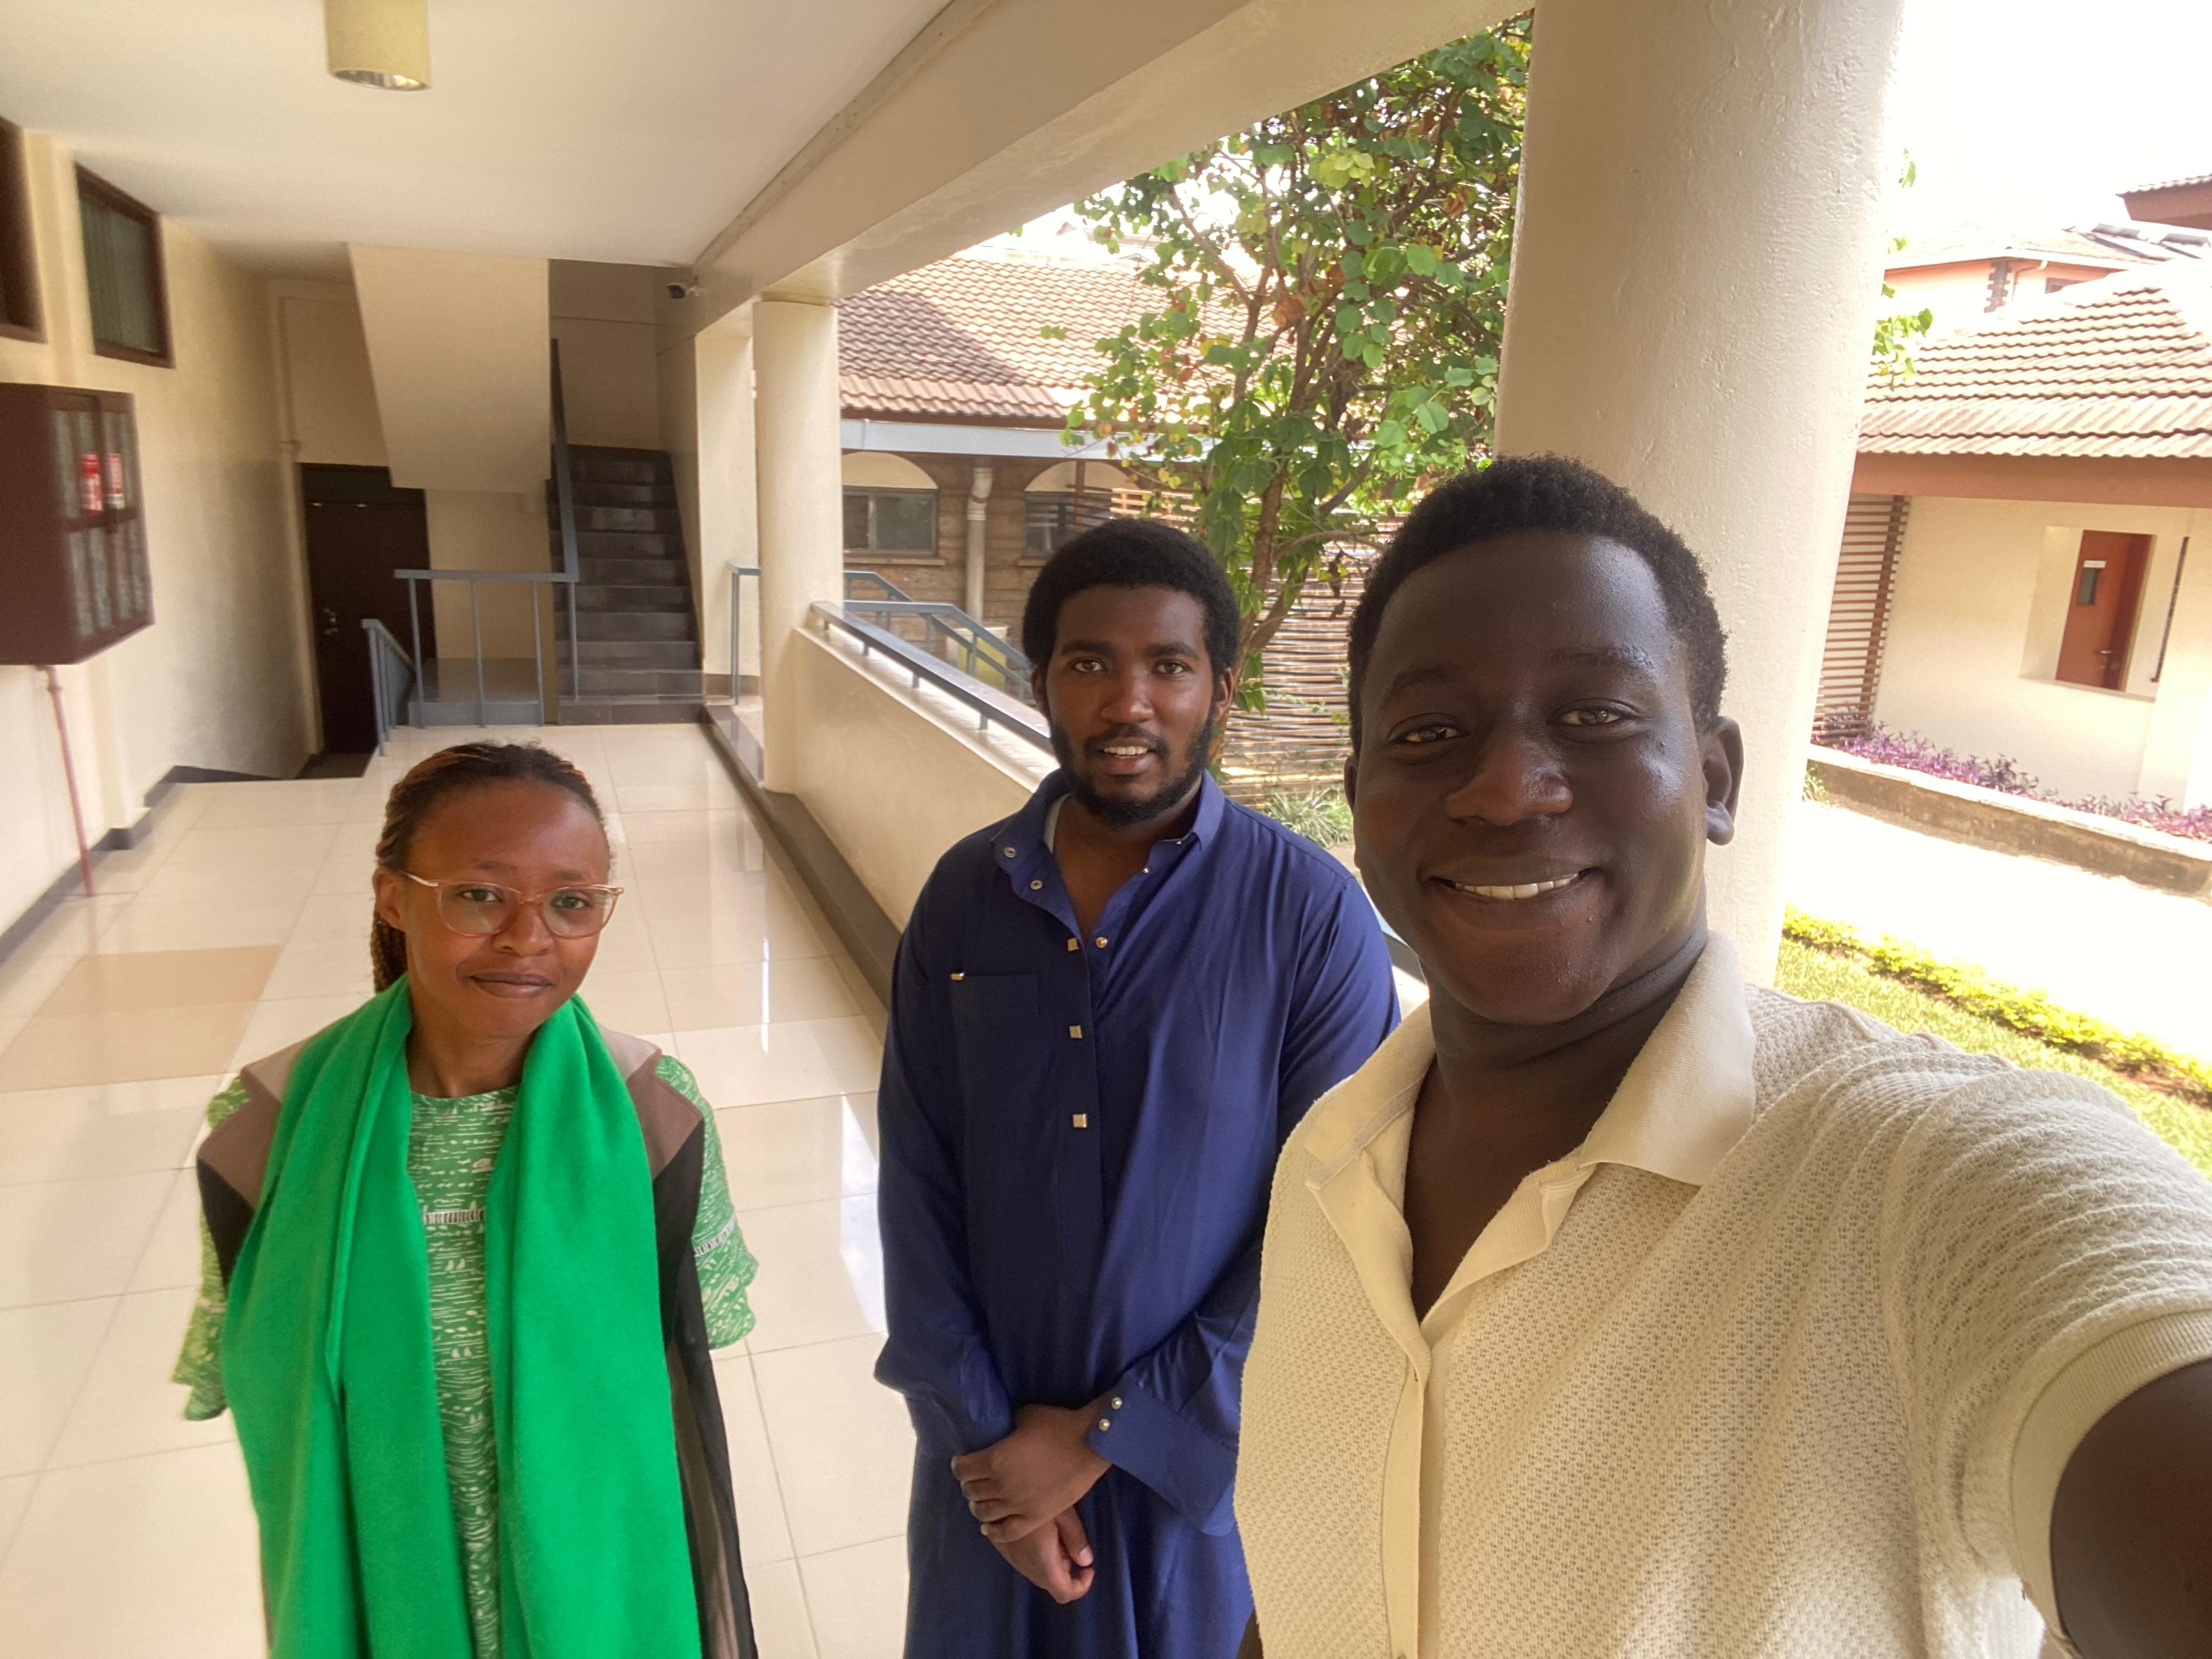